# 2.4 Photo coverage — selected substrate, colour/texture and forecast export

Photograph → **estimated visible projected surface coverage (%)**, overlay, ambiguity envelope and CSV for **2.5**. This does not measure internal colonisation or prove that white material is healthy mycelium.

**First use:** Run All to create `annotation_editor.html`. Open it locally, choose photos, trace the substrate boundary and optionally click examples of mycelium and exposed substrate. Download the annotation JSON. Put its path in `ANNOTATION_JSON`, set `IMAGE_ROOT` to the original-photo folder, and Run All again. Inspect/correct the overlays. Set `reviewed=true` only after checking the resulting segmentation, then rerun for forecast export. The browser tool works offline.

The selected visible substrate is the denominator: **no fixed central crop**. Whole-frame processing requires explicit confirmation. Glare/condensation inside the substrate belong in the uncertainty mask, not background exclusions. Methods need evaluation against reference annotations; no biological accuracy is claimed.

Dependencies: NumPy, pandas, Pillow, matplotlib, IPython. No mycodemo imports, global training on d005/syldd or external model downloads. Outputs go to `models/colonisation/`; original photos remain unchanged.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import base64, hashlib, io, json
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display

WORK_DIR=Path('/home/sylas/Desktop/mycodemo').resolve()
IMAGE_ROOT=WORK_DIR/'data/raw/syldd_2026'
OUTPUT_PARENT=WORK_DIR/'models/colonisation'
ANNOTATION_JSON=None
INOCULATION_DATE=None
WRITE_OUTPUTS=True
BATCH_DEFAULTS={'batch_id':'my-batch','species':'Pleurotus ostreatus','substrate':'straw','view_id':'surface-1'}
import math
def _circle(cx,cy,r,n=48):return [[cx+r*math.cos(2*math.pi*k/n),cy+r*math.sin(2*math.pi*k/n)] for k in range(n)]
PHOTO_RECORDS=[  # two syldd dishes; hand-set circle + one example each, NOT reviewed (software demo only)
 {'image_path':'day_04/IMG_20261012_154516.jpg','batch_id':'syldd-demo','day':4,'roi':{'kind':'polygon','points':_circle(.51,.51,.42)},
  'seeds':[{'label':'mycelium','x':.255,'y':.365,'radius':.015},{'label':'substrate','x':.65,'y':.35,'radius':.015}],'reviewed':False},
 {'image_path':'day_08/IMG_20261016_154903.jpg','batch_id':'syldd-demo','day':8,'roi':{'kind':'polygon','points':_circle(.52,.49,.41)},
  'seeds':[{'label':'mycelium','x':.50,'y':.60,'radius':.015},{'label':'substrate','x':.70,'y':.77,'radius':.015}],'reviewed':False},
]  # actual records only; alternatively load the editor's JSON
# Each record: image_path, day or date, ROI or explicit whole-frame confirmation, optional seed/correction polygons,
# reviewed (bool), selected_for_forecast (bool), method ('auto','seeded','cluster','hsv','manual').
PARAMETERS={'max_side':1000,'default_method':'auto','cluster_count':3,'cluster_sample_pixels':12000,
 'cluster_iterations':25,'random_seed':42,'ambiguous_margin':.18,'minimum_cluster_score_gap':.025,
 'seed_variance_floor':.03,'seed_min_separation':1.,'minimum_roi_pixels':50,
 'max_ambiguous_share_for_forecast':.35,'forecast_tolerance_floor_pct':10.,
 'hsv_value_min':170/255.,'hsv_saturation_max':60/255.,'dark_mean_threshold':.15,'possible_glare_threshold':.02}

def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def output_path(relative):
    path=(WORK_DIR/relative).resolve()
    if not path.is_relative_to(WORK_DIR):raise ValueError('Output must stay inside the project folder.')
    return path
def input_path(value):
    path=Path(value).expanduser()
    return (path if path.is_absolute() else Path(IMAGE_ROOT)/path).resolve()
def finite(value,name,lo=None,hi=None):
    value=float(value)
    if not np.isfinite(value) or (lo is not None and value<lo) or (hi is not None and value>hi):raise ValueError(f'Invalid {name}: {value}')
    return value
def boolean(value,name):
    if not isinstance(value,(bool,np.bool_)):raise ValueError(f'{name} must be boolean, not text.')
    return bool(value)
def json_safe(value):
    if isinstance(value,dict):return {str(k):json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [json_safe(v) for v in value]
    if isinstance(value,np.ndarray):return json_safe(value.tolist())
    if isinstance(value,np.generic):return json_safe(value.item())
    if isinstance(value,float) and not np.isfinite(value):return None
    return value
source_hashes={};records=[dict(row) for row in PHOTO_RECORDS]
if ANNOTATION_JSON is not None:
    annotation_path=Path(ANNOTATION_JSON).expanduser().resolve();source_hashes[str(annotation_path)]=digest(annotation_path)
    document=json.loads(annotation_path.read_text())
    if document.get('schema_version')!=1 or not isinstance(document.get('photos'),list):raise ValueError('Expected annotation schema_version=1 and photos list.')
    records+=document['photos']
print('Photo records:',len(records))
if not records:print('No photos supplied. Run All to generate the editor; no cultivation measurements are invented.')

Photo records: 2


## 1. Explicit substrate masks and aligned images

Images are EXIF-oriented, then reduced to a maximum side of 1000 pixels. Saved masks/counts use working resolution; original dimensions/hashes are retained. Polygon/seed coordinates are normalized 0–1 in that oriented image. ROI polygons, external binary masks, or explicit whole-frame confirmation are supported. Background holes are allowed; do not remove glare/unknown substrate from the denominator.

In [2]:
def load_photo(path):
    with Image.open(path) as raw:
        if getattr(raw,'n_frames',1)!=1:raise ValueError('Use a single still photo.')
        image=ImageOps.exif_transpose(raw)
        if 'A' in image.getbands() and np.asarray(image.getchannel('A')).min()<255:raise ValueError('Use an opaque photograph.')
        image=image.convert('RGB');original_size=image.size
        image.thumbnail((PARAMETERS['max_side'],PARAMETERS['max_side']),Image.Resampling.LANCZOS)
        rgb=np.asarray(image).copy()
    if min(rgb.shape[:2])<8:raise ValueError('Photo too small to inspect.')
    return rgb,original_size

def polygon_points(points):
    if not isinstance(points,(list,tuple)) or len(points)<3:raise ValueError('Polygon needs at least three vertices.')
    pts=np.array([[finite(p[0],'polygon x',0,1),finite(p[1],'polygon y',0,1)] for p in points])
    if len(pts)>256 or len(np.unique(pts,axis=0))<3:raise ValueError('Invalid polygon vertices.')
    area=abs(np.dot(pts[:,0],np.roll(pts[:,1],-1))-np.dot(pts[:,1],np.roll(pts[:,0],-1)))/2
    if area<1e-6:raise ValueError('Polygon area is zero or too small.')
    def orient(a,b,c):return (b[0]-a[0])*(c[1]-a[1])-(b[1]-a[1])*(c[0]-a[0])
    for i in range(len(pts)):
        for j in range(i+1,len(pts)):
            if (j-i)%len(pts) in (1,len(pts)-1):continue
            a,b=pts[i],pts[(i+1)%len(pts)];c,d=pts[j],pts[(j+1)%len(pts)]
            if orient(a,b,c)*orient(a,b,d)<0 and orient(c,d,a)*orient(c,d,b)<0:raise ValueError('Polygon edges cross.')
    return pts

def polygon_mask(points,shape):
    h,w=shape;points=polygon_points(points);image=Image.new('L',(w,h),0)
    ImageDraw.Draw(image).polygon([(round(x*(w-1)),round(y*(h-1))) for x,y in points],fill=255)
    return np.asarray(image)>0

def external_mask(path,shape,original_size):
    with Image.open(path) as raw:
        if raw.mode not in ('1','L'):raise ValueError('External mask must be single-channel binary.')
        image=raw.convert('L')
        if not set(np.unique(np.asarray(image))).issubset({0,255}):raise ValueError('External mask must use 0 and 255.')
        expected=(shape[1],shape[0])
        if image.size not in (tuple(original_size),expected):raise ValueError('Mask must match oriented original or working dimensions.')
        if image.size!=expected:image=image.resize(expected,Image.Resampling.NEAREST)
        return np.asarray(image)>127

def substrate_mask(record,shape,original_size):
    full=boolean(record.get('full_frame_substrate_confirmed',False),'whole-frame confirmation')
    choices=int(record.get('roi') is not None)+int(record.get('roi_mask_path') is not None)+int(full)
    if choices==0:return None,'Trace substrate boundary or explicitly confirm whole-frame substrate.'
    if choices!=1:raise ValueError('Choose one ROI: polygon, external mask or whole frame.')
    if full:mask=np.ones(shape,bool)
    elif record.get('roi_mask_path') is not None:
        path=input_path(record['roi_mask_path']);source_hashes[str(path)]=digest(path);mask=external_mask(path,shape,original_size)
    else:
        if record['roi'].get('kind')!='polygon':raise ValueError('ROI must have kind=polygon.')
        mask=polygon_mask(record['roi']['points'],shape)
    for points in record.get('background_exclusions',[]):mask&=~polygon_mask(points,shape)
    if mask.sum()<PARAMETERS['minimum_roi_pixels']:raise ValueError('Substrate ROI empty or too small.')
    return mask,None

## 2. Per-image colour and texture methods

**Auto** uses labelled examples when both mycelium and exposed-substrate clicks are supplied; otherwise it previews Lab/texture clustering. A bright low-chroma cluster is only a candidate, not biological identity. HSV is retained as a comparison baseline. Manual mode begins with all substrate pixels uncertain, then accepts correction polygons.

Features: Lab lightness/colour, local brightness variation, edge magnitude and saturation. Sample pixels from a click are correlated; they are not independent biological training observations. Clicks must be inside the ROI and contradictory seed patches cannot overlap. No general classifier is trained on d005/syldd.

In [3]:
def box_mean(array,radius=3):
    a=np.pad(np.asarray(array,float),radius,mode='reflect');k=2*radius+1
    integral=np.pad(a,((1,0),(1,0))).cumsum(0).cumsum(1)
    return (integral[k:,k:]-integral[:-k,k:]-integral[k:,:-k]+integral[:-k,:-k])/(k*k)

def image_features(rgb):
    f=rgb.astype(np.float32)/255.;linear=np.where(f<=.04045,f/12.92,((f+.055)/1.055)**2.4)
    xyz=linear@np.array([[.4124564,.3575761,.1804375],[.2126729,.7151522,.0721750],[.0193339,.1191920,.9503041]],np.float32).T
    xyz/=np.array([.95047,1.,1.08883]);lab=np.where(xyz>(6/29)**3,np.cbrt(xyz),xyz/(3*(6/29)**2)+4/29)
    L=116*lab[...,1]-16;a=500*(lab[...,0]-lab[...,1]);b=200*(lab[...,1]-lab[...,2])
    gray=f@np.array([.2126,.7152,.0722]);mean=box_mean(gray);texture=np.sqrt(np.maximum(0,box_mean(gray*gray)-mean*mean))
    gy,gx=np.gradient(gray);edge=np.hypot(gx,gy);v=f.max(axis=2)
    s=np.divide(v-f.min(axis=2),v,out=np.zeros_like(v),where=v>0)
    features=np.stack([L/100,a/128*.7,b/128*.7,np.clip(texture/.15,0,2)*.35,np.clip(edge/.2,0,2)*.2,s*.25],axis=2).astype(np.float32)
    return features,{'gray':gray,'value':v,'saturation':s,'lightness':L}

def hsv_candidate(channels,roi):
    v,s=channels['value'],channels['saturation'];v0=PARAMETERS['hsv_value_min'];s0=PARAMETERS['hsv_saturation_max']
    return ((v>v0)&(s<s0)&roi,((abs(v-v0)<.06)|(abs(s-s0)<.06))&roi,
            {'method':'HSV threshold baseline','notes':['Whiteness is not biological identity.']})

def nearest_centres(flat,centres):
    distances=np.empty((len(flat),len(centres)),np.float32)
    for start in range(0,len(flat),65536):
        block=flat[start:start+65536];distances[start:start+len(block)]=np.sum((block[:,None,:]-centres[None,:,:])**2,axis=2)
    return distances

def cluster_candidate(features,roi):
    flat=features[roi];rng=np.random.default_rng(PARAMETERS['random_seed'])
    sample=flat[rng.choice(len(flat),min(len(flat),PARAMETERS['cluster_sample_pixels']),replace=False)]
    k=min(PARAMETERS['cluster_count'],len(sample))
    if k<2:raise ValueError('Insufficient ROI pixels for clustering.')
    order=np.argsort(sample[:,0]);centres=sample[order[np.linspace(0,len(sample)-1,k).astype(int)]].copy()
    for _ in range(PARAMETERS['cluster_iterations']):
        labels=nearest_centres(sample,centres).argmin(1)
        updated=np.array([sample[labels==j].mean(0) if np.any(labels==j) else centres[j] for j in range(k)])
        if np.allclose(updated,centres,atol=1e-4):break
        centres=updated
    centres=np.unique(np.round(centres,5),axis=0);k=len(centres)
    if k<2:
        return roi.copy(),roi.copy(),{'method':'per-image Lab/texture clustering','cluster_score_gap':0.,'notes':['Uniform ROI: no separable clusters; all pixels uncertain.']}
    distances=nearest_centres(flat,centres);scores=centres[:,0]-.35*np.hypot(centres[:,1]/.7,centres[:,2]/.7)
    chosen=int(np.argmax(scores));other=[j for j in range(k) if j!=chosen]
    dm=distances[:,chosen];ds=distances[:,other].min(1);candidate=dm<=ds
    ambiguous=abs(dm-ds)/(dm+ds+1e-8)<PARAMETERS['ambiguous_margin']
    # Intermediate colour/texture clusters have no verified class identity.
    assigned=distances.argmin(1);darkest=int(np.argmin(scores))
    ambiguous|=(assigned!=chosen)&(assigned!=darkest)
    gap=float(np.sort(scores)[-1]-np.sort(scores)[-2]);notes=['Bright low-chroma cluster is an unverified candidate; inspect pale substrate and glare.']
    if gap<PARAMETERS['minimum_cluster_score_gap']:ambiguous[:]=True;notes.append('No clear cluster separation; add examples or corrections.')
    mask=np.zeros(roi.shape,bool);uncertain=mask.copy();mask[roi]=candidate;uncertain[roi]=ambiguous
    return mask,uncertain,{'method':'per-image Lab/texture clustering','cluster_score_gap':gap,'notes':notes}

def seed_masks(seeds,roi):
    h,w=roi.shape;yy,xx=np.ogrid[:h,:w];masks={label:np.zeros(roi.shape,bool) for label in ['mycelium','substrate']};counts={label:0 for label in masks}
    for seed in seeds:
        label=seed.get('label')
        if label not in masks:raise ValueError('Seed label must be mycelium or substrate.')
        x=finite(seed['x'],'seed x',0,1)*(w-1);y=finite(seed['y'],'seed y',0,1)*(h-1)
        if not roi[round(y),round(x)]:raise ValueError('Example outside substrate ROI.')
        radius=max(1.,finite(seed.get('radius',.015),'seed radius',.001,.1)*min(h,w))
        masks[label]|=(((xx-x)**2+(yy-y)**2)<=radius**2)&roi;counts[label]+=1
    if np.any(masks['mycelium']&masks['substrate']):raise ValueError('Contradictory example patches overlap.')
    return masks,counts

def seeded_candidate(features,roi,seeds):
    masks,counts=seed_masks(seeds,roi)
    if any(not masks[label].any() for label in masks):raise ValueError('Need examples of both mycelium and exposed substrate.')
    examples=[features[masks[label]] for label in ['mycelium','substrate']];centres=np.array([v.mean(0) for v in examples])
    scale=np.sqrt(np.mean([v.var(0) for v in examples],axis=0)+PARAMETERS['seed_variance_floor']**2)
    separation=float(np.linalg.norm((centres[0]-centres[1])/scale));distances=nearest_centres(features[roi]/scale,centres/scale)
    candidate=distances[:,0]<=distances[:,1]
    ambiguous=abs(distances[:,0]-distances[:,1])/(distances.sum(1)+1e-8)<PARAMETERS['ambiguous_margin']
    ambiguous|=distances.min(1)>25.;notes=['Per-image example matching, not a biological identity detector.']
    if separation<PARAMETERS['seed_min_separation']:ambiguous[:]=True;notes.append('Examples poorly separated; add informative examples.')
    mask=np.zeros(roi.shape,bool);uncertain=mask.copy();mask[roi]=candidate;uncertain[roi]=ambiguous
    return mask,uncertain,{'method':'per-image colour/texture examples','example_clicks':counts,'sample_pixels':{k:int(v.sum()) for k,v in masks.items()},'separation':separation,'notes':notes}

def segment(rgb,roi,record):
    features,channels=image_features(rgb);method=record.get('method',PARAMETERS['default_method']);seeds=record.get('seeds',[])
    if method not in ('auto','seeded','cluster','hsv','manual'):raise ValueError('Unknown method.')
    hsv=hsv_candidate(channels,roi);comparisons={'HSV baseline':100*float(hsv[0].sum()/roi.sum())}
    if method=='auto':method='seeded' if {'mycelium','substrate'}.issubset({s.get('label') for s in seeds}) else 'cluster'
    if method=='hsv':mask,uncertain,details=hsv
    elif method=='seeded':mask,uncertain,details=seeded_candidate(features,roi,seeds)
    elif method=='manual':mask=np.zeros(roi.shape,bool);uncertain=roi.copy();details={'method':'manual correction polygons','notes':['Unlabelled ROI begins uncertain; last correction wins.']}
    else:
        if seeds:seed_masks(seeds,roi)
        mask,uncertain,details=cluster_candidate(features,roi)
    comparisons[details['method']]=100*float(mask.sum()/roi.sum())
    for correction in record.get('corrections',[]):
        label=correction.get('label')
        if label not in ('mycelium','substrate','uncertain'):raise ValueError('Unknown correction label.')
        region=polygon_mask(correction['points'],roi.shape)&roi
        if label=='mycelium':mask[region]=True;uncertain[region]=False
        elif label=='substrate':mask[region]=False;uncertain[region]=False
        else:uncertain[region]=True
    return mask&roi,uncertain&roi,details,channels,comparisons

## 3. Coverage, ambiguity and quality

Coverage = nominal mycelium pixels / substrate-mask pixels × 100. Ambiguous pixels remain in the denominator. The lower bound counts only non-ambiguous mycelium; the upper counts all ambiguous pixels as potentially mycelium. The nominal value retains the algorithm's guess in ambiguous regions. This is an ambiguity envelope, **not a confidence interval or complete error bound**.

Review is required for forecast export. Excessive ambiguity, very dark images, missing dates or duplicate selected measurements block export. Glare and blur statistics are heuristic aids, not validated quality tests. The minimum 10 percentage-point forecast tolerance is an explicit demo weighting assumption. Human review does not make biological identity certain.

In [4]:
def coverage_statistics(mask,uncertain,roi):
    n=int(roi.sum())
    if n==0:raise ValueError('Empty substrate denominator.')
    nominal=100*float((mask&roi).sum())/n;lower=100*float((mask&roi&~uncertain).sum())/n
    upper=100*float(((mask&roi&~uncertain)|(uncertain&roi)).sum())/n
    return {'substrate_pixels':n,'nominal_mycelium_pixels':int((mask&roi).sum()),'ambiguous_pixels':int((uncertain&roi).sum()),
            'coverage_pct':nominal,'coverage_lower_pct':lower,'coverage_upper_pct':upper,
            'uncertainty_pct':max(PARAMETERS['forecast_tolerance_floor_pct'],nominal-lower,upper-nominal)}

def photo_quality(rgb,roi,channels):
    gray=channels['gray'];brightness=float(gray[roi].mean());glare=float((rgb.min(2)[roi]>=250).mean())
    lap=-4*gray+np.roll(gray,1,0)+np.roll(gray,-1,0)+np.roll(gray,1,1)+np.roll(gray,-1,1)
    dark=brightness<PARAMETERS['dark_mean_threshold'];notes=[]
    if dark:notes.append('Very dark substrate region; retake or review lighting.')
    if glare>PARAMETERS['possible_glare_threshold']:notes.append('Possible glare/very white surface; inspect the overlay.')
    return {'mean_brightness':brightness,'possible_glare_fraction':glare,'laplacian_variance':float(lap[roi].var()),'dark':dark,'notes':notes}

def observation_day(record):
    day=None if record.get('day') is None else finite(record['day'],'day',0)
    if record.get('date') not in (None,''):
        if INOCULATION_DATE is None:
            if day is None:return None,'Date needs INOCULATION_DATE or elapsed day.'
        else:
            observed,inoc=pd.Timestamp(record['date']),pd.Timestamp(INOCULATION_DATE)
            if pd.isna(observed) or pd.isna(inoc):raise ValueError('Invalid date.')
            try:derived=finite((observed-inoc).total_seconds()/86400.,'date-derived day',0)
            except TypeError as exc:raise ValueError('Use matching timezone conventions.') from exc
            if day is not None and not np.isclose(day,derived):raise ValueError('day/date disagree.')
            day=derived
    return (day,None) if day is not None else (None,'Enter elapsed day or a date with INOCULATION_DATE.')

def overlay_image(rgb,mask,uncertain,roi):
    out=rgb.astype(float).copy();region=mask&~uncertain;out[region]=.55*out[region]+.45*np.array([225,20,185])
    region=uncertain&roi;out[region]=.35*out[region]+.65*np.array([255,176,0])
    pad=np.pad(roi,1,constant_values=False);inside=roi&pad[:-2,1:-1]&pad[2:,1:-1]&pad[1:-1,:-2]&pad[1:-1,2:]
    out[roi&~inside]=[0,230,235]
    return np.clip(out,0,255).astype(np.uint8)

def analyse_record(record,index):
    path=input_path(record['image_path']);sha=digest(path);source_hashes[str(path)]=sha
    if record.get('image_sha256') not in (None,'',sha):raise ValueError('Source image hash differs from annotation.')
    rgb,original_size=load_photo(path);metadata={k:record.get(k) or v for k,v in BATCH_DEFAULTS.items()}
    if not str(metadata['batch_id']).strip():raise ValueError('batch_id required.')
    entry={'index':index,'image_path':str(path),'image_sha256':sha,'photo_id':str(record.get('photo_id') or sha),**metadata,
           'original_width':original_size[0],'original_height':original_size[1],'working_width':rgb.shape[1],'working_height':rgb.shape[0],
           'reviewed':boolean(record.get('reviewed',False),'reviewed'),'selected_for_forecast':boolean(record.get('selected_for_forecast',True),'selected_for_forecast')}
    roi,message=substrate_mask(record,rgb.shape[:2],original_size)
    if roi is None:return {'entry':{**entry,'status':'needs_substrate_boundary','quality_ok':False,'notes':[message]},'rgb':rgb,'record':record}
    mask,uncertain,details,channels,comparison=segment(rgb,roi,record);stats=coverage_statistics(mask,uncertain,roi);quality=photo_quality(rgb,roi,channels)
    day,day_message=observation_day(record);reasons=[]
    if not entry['reviewed']:reasons.append('Overlay not yet marked reviewed.')
    if not entry['selected_for_forecast']:reasons.append('View not selected for forecasting.')
    if stats['ambiguous_pixels']/stats['substrate_pixels']>PARAMETERS['max_ambiguous_share_for_forecast']:reasons.append('Too much ambiguous area; add examples/corrections or retake.')
    if quality['dark']:reasons.append('Very dark ROI blocks forecast export.')
    if day_message:reasons.append(day_message)
    entry.update(stats);entry.update({'day':day,'coverage_fraction':stats['coverage_pct']/100.,'method':details['method'],
        'quality_ok':not reasons,'status':'forecast_ready' if not reasons else 'review_required','blocking_reasons':reasons,
        'notes':details['notes']+quality['notes'],'quality_metrics':quality,'method_details':details,'method_comparison_pct':comparison})
    evaluation=None
    if record.get('reference_mycelium_mask_path') is not None:
        rp=input_path(record['reference_mycelium_mask_path']);source_hashes[str(rp)]=digest(rp);truth=external_mask(rp,rgb.shape[:2],original_size)
        if np.any(truth&~roi):raise ValueError('Reference mycelium extends outside ROI.')
        intersection=int((mask&truth).sum());union=int((mask|truth).sum());total=int(mask.sum()+truth.sum());true_pct=100*float(truth.sum())/roi.sum()
        evaluation={'reference_path':str(rp),'reference_coverage_pct':true_pct,'absolute_coverage_error_pct_points':abs(true_pct-stats['coverage_pct']),
                    'iou':1. if union==0 else intersection/union,'dice':1. if total==0 else 2*intersection/total,
                    'basis':'user-provided annotation; not independent biological verification'}
    return {'entry':entry,'rgb':rgb,'roi':roi,'mask':mask,'uncertain':uncertain,'overlay':overlay_image(rgb,mask,uncertain,roi),'record':record,'evaluation':evaluation}

def enforce_unique_measurements(items):
    identities={};photo_ids={};times={}
    for item in items:
        e=item['entry']
        if e.get('quality_ok'):
            identities.setdefault(e['image_sha256'],[]).append(e)
            photo_ids.setdefault(e['photo_id'],[]).append(e)
            times.setdefault((e['batch_id'],e['day']),[]).append(e)
    for group in list(identities.values())+list(photo_ids.values())+list(times.values()):
        if len(group)>1:
            for e in group:
                e['quality_ok']=False;e['status']='duplicate_review_required'
                e.setdefault('blocking_reasons',[]).append('Duplicate image or selected batch/day; choose one representative measurement.')

## 4. Inspect each overlay

Magenta = classified mycelium, amber = ambiguous, cyan = substrate boundary. Correction polygons are applied in order; the last overlapping correction wins. Use the same surface/view over time. Unreviewed estimates are previews and do not enter the 2.5-ready CSV.

,index,image_path,image_sha256,photo_id,batch_id,species,substrate,view_id,original_width,original_height,...,ambiguous_pixels,coverage_pct,coverage_lower_pct,coverage_upper_pct,uncertainty_pct,day,coverage_fraction,method,quality_ok,status
0,0,/home/sylas/Desktop/mycodemo/data/raw/syldd_20...,95aaf26dd789383cd08447ec99e67effdfd9e65a540832...,95aaf26dd789383cd08447ec99e67effdfd9e65a540832...,syldd-demo,Pleurotus ostreatus,straw,surface-1,3072,3072,...,67695,47.193364,41.501666,53.762588,10.0,4.0,0.471934,per-image colour/texture examples,False,review_required
1,1,/home/sylas/Desktop/mycodemo/data/raw/syldd_20...,e39c1506111a46fdccc018f6c3538756be2d3537eecf9b...,e39c1506111a46fdccc018f6c3538756be2d3537eecf9b...,syldd-demo,Pleurotus ostreatus,straw,surface-1,3072,3072,...,40710,76.682558,73.101503,80.839958,10.0,8.0,0.766826,per-image colour/texture examples,False,review_required


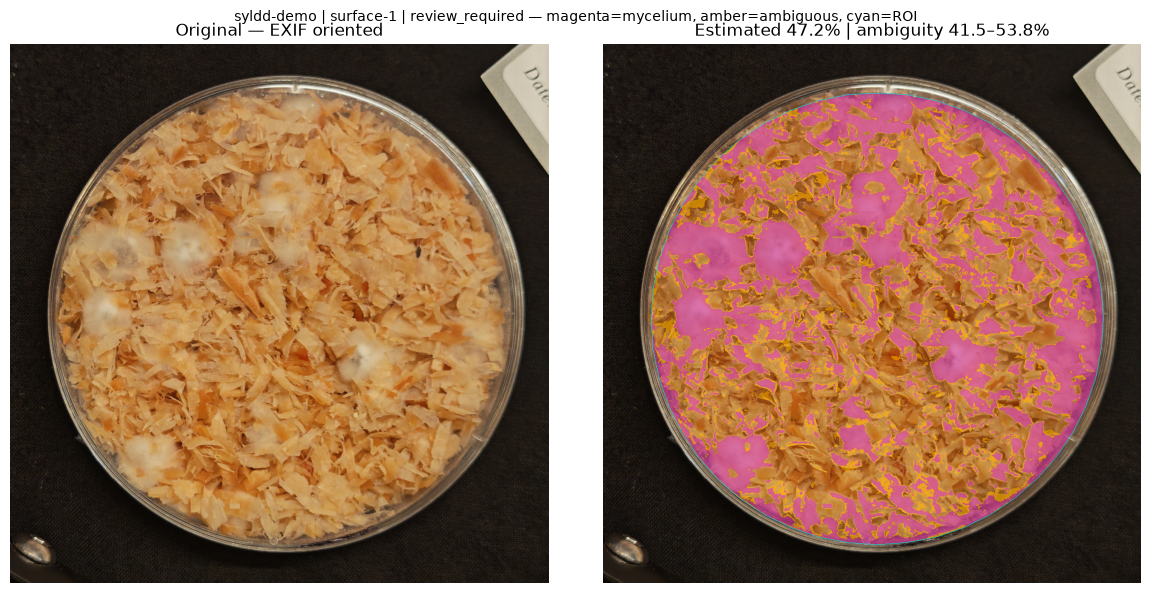

- Overlay not yet marked reviewed.


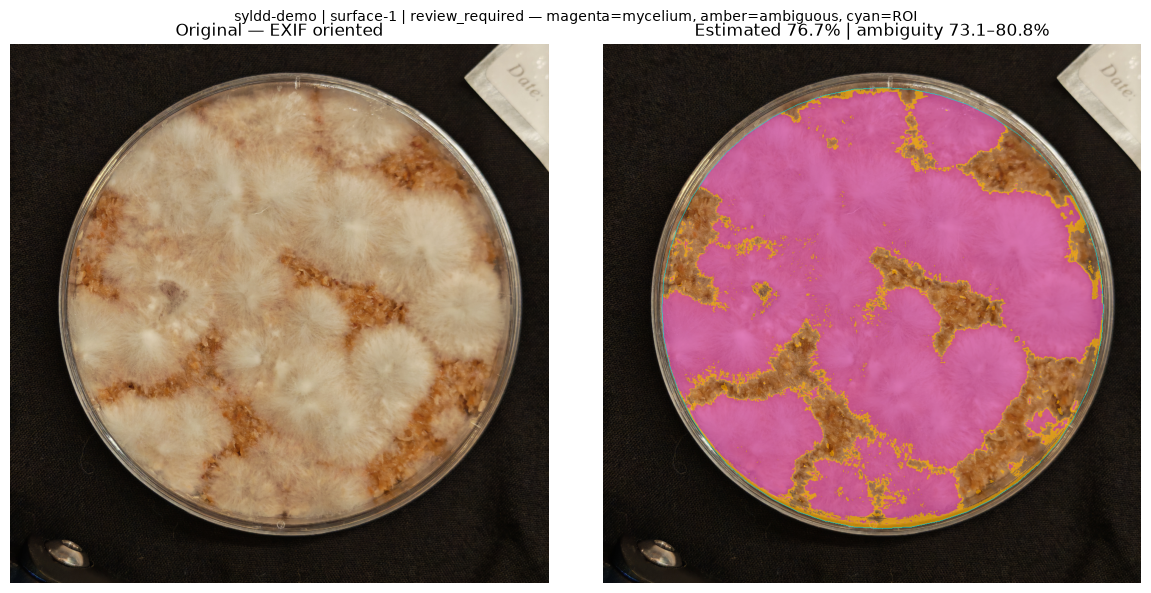

- Overlay not yet marked reviewed.
Forecast-ready: 0


In [5]:
results=[];errors=[]
for index,record in enumerate(records):
    try:results.append(analyse_record(record,index))
    except (ValueError,KeyError,OSError,TypeError) as exc:errors.append({'index':index,'image_path':str(record.get('image_path','')),'error':str(exc)})
enforce_unique_measurements(results)
summary=pd.DataFrame([{k:v for k,v in item['entry'].items() if k not in ['quality_metrics','method_details','method_comparison_pct','notes','blocking_reasons']} for item in results])
if summary.empty:summary=pd.DataFrame(columns=['index','image_path','photo_id','batch_id','day','coverage_pct','quality_ok','status'])
if not summary.empty:display(summary)
if errors:display(pd.DataFrame(errors))
figures={}
for item in results:
    e=item['entry'];fig,axes=plt.subplots(1,2,figsize=(12,6));axes[0].imshow(item['rgb']);axes[0].set_title('Original — EXIF oriented')
    if 'overlay' in item:
        axes[1].imshow(item['overlay']);axes[1].set_title(f"Estimated {e['coverage_pct']:.1f}% | ambiguity {e['coverage_lower_pct']:.1f}–{e['coverage_upper_pct']:.1f}%")
    else:axes[1].imshow(item['rgb']);axes[1].set_title('Boundary needed; no percentage calculated')
    for ax in axes:ax.axis('off')
    fig.suptitle(f"{e['batch_id']} | {e['view_id']} | {e['status']} — magenta=mycelium, amber=ambiguous, cyan=ROI",fontsize=10)
    fig.tight_layout();figures[e['index']]=fig;plt.show()
    for reason in e.get('blocking_reasons',e.get('notes',[])):print('- '+reason)
print('Forecast-ready:',sum(bool(item['entry'].get('quality_ok')) for item in results))

## 5. Offline annotation editor

Choose photos. In boundary/correction mode, click vertices and press **Finish polygon**. In example modes, click representative mycelium or exposed substrate. Download JSON and load it through `ANNOTATION_JSON`.

For photos already listed here the editor embeds oriented previews and original paths. New browser-selected photos supply filenames only: set `IMAGE_ROOT` to their directory. The browser cannot disclose full filesystem paths. The review checkbox means you inspected the resulting notebook overlay; it is not automatically set by drawing examples.

In [6]:
EDITOR_HTML = '<!doctype html>\n<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Photo coverage — annotate substrate</title>\n<style>\n*{box-sizing:border-box}body{margin:0;background:#f3f5f3;color:#20372f;font:15px system-ui,sans-serif}header{padding:22px 28px;background:#173b31;color:#fff}header h1{font-size:24px;margin:0 0 8px}header p{margin:0;color:#cde2d6;max-width:1000px}main{max-width:1500px;margin:auto;padding:20px;display:grid;grid-template-columns:290px 1fr;gap:18px}.panel{background:white;border:1px solid #d8e1da;border-radius:12px;padding:18px}h2{font-size:17px;margin:0 0 12px}label{display:block;margin:10px 0 4px;font-weight:600}input,select,button{font:inherit}input[type=text],input[type=number],input[type=date],select{width:100%;padding:8px;border:1px solid #b4c6bb;border-radius:6px}input[type=file]{width:100%}button{padding:9px 12px;border-radius:7px;border:1px solid #9bb5a4;background:#f7faf8;color:#20372f;cursor:pointer}button:hover{background:#dfebe3}button.primary{background:#28684f;color:#fff;border-color:#28684f}.row{display:flex;gap:8px;flex-wrap:wrap}.row>*{flex:1}.modes{display:flex;flex-wrap:wrap;gap:7px;margin:12px 0}.modes button{flex:1 1 145px}.modes button.active{background:#d2eee1;border-color:#27674f;box-shadow:inset 0 0 0 1px #27674f}canvas{display:block;max-width:100%;height:auto;margin:auto;cursor:crosshair;background:#e9edeb;border:1px solid #d1dcd5}.hint{font-size:13px;color:#52695b;line-height:1.5}.check{display:flex;gap:8px;align-items:flex-start;font-size:13px;font-weight:400}.check input{margin-top:4px}#status{margin:12px 0;padding:10px;border-radius:6px;background:#edf4ef;min-height:40px}.warning{background:#fff4da;padding:12px;border-radius:8px;font-size:13px;line-height:1.5}.metadata{display:grid;grid-template-columns:1fr 1fr;gap:0 12px}.count{font-size:13px;color:#52695b}.space{margin-top:14px}@media(max-width:850px){main{grid-template-columns:1fr}.metadata{grid-template-columns:1fr}}\n</style></head><body>\n<header><h1>Photo coverage</h1><p>Select the visible substrate, give examples, and correct uncertain regions. Everything stays in this browser; no photo is uploaded. Run notebook 2.4 to calculate the percentage and inspect the segmentation.</p></header>\n<main><aside class="panel"><h2>1. Choose photos</h2><input id="files" type="file" accept="image/*" multiple><label for="photos">Selected photo</label><select id="photos"></select><div class="row space"><button id="previous">Previous</button><button id="next">Next</button></div><p id="filename" class="count">No photo selected</p>\n<h2 class="space">2. Record the observation</h2><label for="batch">Batch ID</label><input id="batch" type="text" value="my-batch"><label for="view">Surface / view ID</label><input id="view" type="text" value="surface-1"><label for="species">Species</label><input id="species" type="text" value="Pleurotus ostreatus"><label for="substrate">Substrate</label><input id="substrate" type="text" value="straw"><div class="metadata"><div><label for="day">Elapsed day</label><input id="day" type="number" min="0" step="any"></div><div><label for="date">Photo date</label><input id="date" type="date"></div></div><p class="hint">Use elapsed day, or a date plus INOCULATION_DATE in the notebook. If you supply both, they must agree.</p>\n<label for="method">Method</label><select id="method"><option value="auto">Auto: examples, otherwise clustering</option><option value="seeded">Examples only (both labels required)</option><option value="cluster">Colour + texture clustering</option><option value="hsv">HSV comparison baseline</option><option value="manual">Manual correction polygons</option></select><label for="radius">Example radius (% of short side)</label><input id="radius" type="number" min="0.1" max="10" step="0.1" value="1.5">\n<label class="check"><input id="whole" type="checkbox"><span>The entire frame is visible substrate, with no background or container. This replaces a drawn boundary.</span></label><label class="check"><input id="selected" type="checkbox" checked><span>Use this view in the forecast (one selected measurement per batch/day).</span></label><label class="check"><input id="reviewed" type="checkbox"><span>I have inspected the resulting notebook segmentation overlay and corrected it where needed.</span></label>\n<h2 class="space">3. Save annotations</h2><button id="download" class="primary">Download annotation JSON</button><label for="annotationFile">Reload saved annotations</label><input id="annotationFile" type="file" accept=".json,application/json"><p class="hint">Set ANNOTATION_JSON to the downloaded file in notebook 2.4. For newly chosen photos, set IMAGE_ROOT to their original folder. No full filesystem path is available from the browser.</p></aside>\n<section class="panel"><h2>Trace and label the substrate</h2><div class="modes" id="modes"><button data-mode="roi" class="active">Substrate boundary</button><button data-mode="mycelium_seed">Mycelium example</button><button data-mode="substrate_seed">Exposed-substrate example</button><button data-mode="mycelium">Correct: mycelium polygon</button><button data-mode="substrate">Correct: exposed polygon</button><button data-mode="uncertain">Mark uncertain polygon</button><button data-mode="background">Exclude background hole</button></div>\n<div class="row"><button id="finish">Finish polygon (Enter)</button><button id="undo">Undo</button><button id="clearPending">Cancel unfinished polygon</button><button id="clearSeeds">Clear examples</button><button id="clearCorrections">Clear corrections</button><button id="clearRoi">Clear boundary</button></div><div id="status">Choose a photo to begin.</div><canvas id="canvas" width="900" height="520"></canvas>\n<p class="hint">Polygon mode: click vertices, then Finish polygon. Example mode: click representative patches. Cyan = substrate outline; magenta = mycelium examples/corrections; green = exposed substrate; amber = uncertainty. These are annotations, not computed segmentation. Last overlapping correction wins.</p>\n<div class="warning">Keep glare and condensation inside the substrate denominator: mark them uncertain. Exclude only actual background/container holes. A pale substrate or white contaminant may resemble mycelium. For manual mode, label the ROI as exposed first, then add mycelium polygons; unlabelled pixels otherwise remain uncertain.</div></section></main>\n<script>\n\'use strict\';\nconst initial=__INITIAL_PREVIEWS__;\nconst $=id=>document.getElementById(id);const canvas=$(\'canvas\'),ctx=canvas.getContext(\'2d\');\nlet photos=[],index=-1,mode=\'roi\',pending=[],undoStack=[];\nfunction clone(x){return JSON.parse(JSON.stringify(x));}\nfunction base(record={}){return {image_path:\'\',photo_id:\'\',batch_id:\'my-batch\',species:\'Pleurotus ostreatus\',substrate:\'straw\',view_id:\'surface-1\',method:\'auto\',seeds:[],corrections:[],background_exclusions:[],reviewed:false,selected_for_forecast:true,full_frame_substrate_confirmed:false,...record};}\nfunction current(){return index>=0?photos[index]:null;}\nfunction message(s){$(\'status\').textContent=s;}\nfunction pushUndo(){if(current())undoStack.push(clone(current().record));}\nfunction changed(){if(current()){current().record.reviewed=false;$(\'reviewed\').checked=false;}draw();}\nfunction readFields(){const p=current();if(!p)return;const r=p.record;for(const [field,id] of [[\'batch_id\',\'batch\'],[\'species\',\'species\'],[\'substrate\',\'substrate\'],[\'view_id\',\'view\']])r[field]=$(id).value.trim();r.method=$(\'method\').value;r.reviewed=$(\'reviewed\').checked;r.selected_for_forecast=$(\'selected\').checked;r.full_frame_substrate_confirmed=$(\'whole\').checked;if($(\'day\').value===\'\')delete r.day;else r.day=Number($(\'day\').value);if($(\'date\').value===\'\')delete r.date;else r.date=$(\'date\').value;}\nfunction refreshList(){$(\'photos\').replaceChildren();photos.forEach((p,i)=>{const o=document.createElement(\'option\');o.value=String(i);o.textContent=(i+1)+\'. \'+p.record.image_path.split(/[\\\\/]/).pop();$(\'photos\').appendChild(o);});$(\'photos\').value=String(index);}\nfunction show(i,preserveUndo=false){readFields();index=i;pending=[];if(!preserveUndo)undoStack=[];const p=current();if(!p)return;const r=p.record;refreshList();for(const [field,id] of [[\'batch_id\',\'batch\'],[\'species\',\'species\'],[\'substrate\',\'substrate\'],[\'view_id\',\'view\']])$(id).value=r[field]||\'\';$(\'day\').value=r.day??\'\';$(\'date\').value=r.date||\'\';$(\'method\').value=r.method||\'auto\';$(\'whole\').checked=!!r.full_frame_substrate_confirmed;$(\'reviewed\').checked=!!r.reviewed;$(\'selected\').checked=r.selected_for_forecast!==false;$(\'filename\').textContent=r.image_path;if(p.image){const scale=Math.min(1,1000/Math.max(p.image.naturalWidth,p.image.naturalHeight));canvas.width=Math.round(p.image.naturalWidth*scale);canvas.height=Math.round(p.image.naturalHeight*scale);}message(p.image?\'Choose a mode. Trace the visible substrate first.\':\'Choose the matching original image file to display this saved annotation.\');draw();}\nfunction polygon(points,colour,fill=true,close=true){if(!points?.length)return;ctx.beginPath();points.forEach(([x,y],i)=>{i?ctx.lineTo(x*canvas.width,y*canvas.height):ctx.moveTo(x*canvas.width,y*canvas.height);});if(close)ctx.closePath();ctx.strokeStyle=colour;ctx.lineWidth=2;if(fill&&close){ctx.globalAlpha=.17;ctx.fillStyle=colour;ctx.fill();ctx.globalAlpha=1;}ctx.stroke();for(const [x,y] of points){ctx.beginPath();ctx.arc(x*canvas.width,y*canvas.height,3,0,Math.PI*2);ctx.fillStyle=colour;ctx.fill();}}\nfunction draw(){ctx.clearRect(0,0,canvas.width,canvas.height);const p=current();if(!p?.image){ctx.fillStyle=\'#52695b\';ctx.font=\'20px system-ui\';ctx.fillText(\'Choose a substrate photo\',35,65);return;}ctx.drawImage(p.image,0,0,canvas.width,canvas.height);const r=p.record;if(r.roi?.points)polygon(r.roi.points,\'#00d9df\',false);if(r.full_frame_substrate_confirmed)polygon([[0,0],[1,0],[1,1],[0,1]],\'#00d9df\',false);for(const points of r.background_exclusions||[])polygon(points,\'#777\');for(const c of r.corrections||[])polygon(c.points,c.label===\'mycelium\'?\'#e114b9\':c.label===\'substrate\'?\'#20a56a\':\'#ffb000\');for(const s of r.seeds||[]){ctx.beginPath();ctx.arc(s.x*canvas.width,s.y*canvas.height,(s.radius||.015)*Math.min(canvas.width,canvas.height),0,Math.PI*2);ctx.strokeStyle=s.label===\'mycelium\'?\'#ff21ce\':\'#00f594\';ctx.lineWidth=3;ctx.stroke();ctx.fillStyle=ctx.strokeStyle;ctx.font=\'bold 14px system-ui\';ctx.fillText(s.label===\'mycelium\'?\'M\':\'S\',s.x*canvas.width+5,s.y*canvas.height-5);}polygon(pending,\'#fff\',false,false);}\nasync function decoded(src){return new Promise((resolve,reject)=>{const image=new Image();image.onload=()=>resolve(image);image.onerror=()=>reject(new Error(\'Cannot decode image\'));image.src=src;});}\n$(\'files\').addEventListener(\'change\',async e=>{readFields();for(const file of e.target.files){try{const url=URL.createObjectURL(file);const image=await decoded(url);URL.revokeObjectURL(url);let hash;try{const bytes=await crypto.subtle.digest(\'SHA-256\',await file.arrayBuffer());hash=Array.from(new Uint8Array(bytes),x=>x.toString(16).padStart(2,\'0\')).join(\'\');}catch{}const existing=photos.find(p=>p.record.image_path.split(/[\\\\/]/).pop()===file.name);if(existing){existing.image=image;if(hash)existing.record.image_sha256=hash;}else photos.push({record:base({image_path:file.name,photo_id:file.name,...(hash?{image_sha256:hash}:{})}),image});}catch(error){message(file.name+\': \'+error.message);}}if(photos.length)show(photos.length-1);e.target.value=\'\';});\n$(\'photos\').addEventListener(\'change\',e=>show(Number(e.target.value)));$(\'previous\').onclick=()=>{if(index>0)show(index-1);};$(\'next\').onclick=()=>{if(index+1<photos.length)show(index+1);};\n$(\'modes\').addEventListener(\'click\',e=>{const b=e.target.closest(\'button[data-mode]\');if(!b)return;if(pending.length){message(\'Finish or cancel the unfinished polygon before switching mode.\');return;}mode=b.dataset.mode;for(const x of $(\'modes\').querySelectorAll(\'button\'))x.classList.toggle(\'active\',x===b);message(mode.endsWith(\'_seed\')?\'Click a representative patch.\':\'Click polygon vertices, then Finish polygon.\');});\ncanvas.addEventListener(\'click\',e=>{const p=current();if(!p?.image)return;const rect=canvas.getBoundingClientRect();const x=Math.min(1,Math.max(0,(e.clientX-rect.left)/rect.width)),y=Math.min(1,Math.max(0,(e.clientY-rect.top)/rect.height));if(mode.endsWith(\'_seed\')){pushUndo();const label=mode===\'mycelium_seed\'?\'mycelium\':\'substrate\';p.record.seeds.push({label,x,y,radius:Math.min(.1,Math.max(.001,Number($(\'radius\').value)/100))});changed();message(\'Example added. Use several representative patches if needed.\');}else{pending.push([x,y]);draw();message(pending.length+\' vertices. Finish polygon when the boundary is complete.\');}});\nfunction finish(){const p=current();if(!p)return;if(pending.length<3){message(\'A polygon needs at least three vertices.\');return;}pushUndo();if(mode===\'roi\'){p.record.roi={kind:\'polygon\',points:clone(pending)};delete p.record.roi_mask_path;p.record.full_frame_substrate_confirmed=false;$(\'whole\').checked=false;}else if(mode===\'background\')p.record.background_exclusions.push(clone(pending));else if([\'mycelium\',\'substrate\',\'uncertain\'].includes(mode))p.record.corrections.push({label:mode,points:clone(pending)});pending=[];changed();message(\'Polygon saved. Add examples/corrections or download the annotations.\');}\n$(\'finish\').onclick=finish;document.addEventListener(\'keydown\',e=>{if(e.key===\'Enter\'&&e.target.tagName!==\'INPUT\'&&e.target.tagName!==\'SELECT\'){e.preventDefault();finish();}});\n$(\'clearPending\').onclick=()=>{pending=[];draw();};$(\'undo\').onclick=()=>{if(pending.length){pending.pop();draw();}else if(undoStack.length&&current()){current().record=undoStack.pop();const i=index;index=-1;show(i,true);}};\n$(\'clearSeeds\').onclick=()=>{if(current()){pushUndo();current().record.seeds=[];changed();}};$(\'clearCorrections\').onclick=()=>{if(current()){pushUndo();current().record.corrections=[];changed();}};$(\'clearRoi\').onclick=()=>{if(current()){pushUndo();delete current().record.roi;delete current().record.roi_mask_path;current().record.background_exclusions=[];current().record.full_frame_substrate_confirmed=false;$(\'whole\').checked=false;changed();}};\nfor(const id of [\'batch\',\'view\',\'species\',\'substrate\',\'day\',\'date\',\'selected\',\'reviewed\'])$(id).addEventListener(\'change\',readFields);\n$(\'method\').addEventListener(\'change\',()=>{readFields();changed();});$(\'whole\').addEventListener(\'change\',()=>{if(!current())return;pushUndo();if($(\'whole\').checked){delete current().record.roi;delete current().record.roi_mask_path;current().record.background_exclusions=[];}readFields();changed();});\n$(\'download\').onclick=()=>{readFields();if(!photos.length){message(\'Choose at least one photo before downloading annotations.\');return;}if(pending.length){message(\'Finish or cancel the unfinished polygon first.\');return;}const doc={schema_version:1,coordinate_system:\'normalized EXIF-oriented image\',photos:photos.map(p=>clone(p.record))};const a=document.createElement(\'a\');a.href=URL.createObjectURL(new Blob([JSON.stringify(doc,null,2)],{type:\'application/json\'}));a.download=\'photo_annotations.json\';a.click();setTimeout(()=>URL.revokeObjectURL(a.href),1000);message(\'Downloaded. Load this JSON in notebook 2.4; original image files are still needed.\');};\n$(\'annotationFile\').addEventListener(\'change\',async e=>{const file=e.target.files[0];if(!file)return;try{const doc=JSON.parse(await file.text());if(doc.schema_version!==1||!Array.isArray(doc.photos))throw new Error(\'Unsupported annotation schema\');readFields();for(const record of doc.photos){const existing=photos.find(p=>p.record.image_path===record.image_path||p.record.image_path.split(/[\\\\/]/).pop()===record.image_path.split(/[\\\\/]/).pop());if(existing)existing.record=base(record);else photos.push({record:base(record),image:null});}if(photos.length){index=-1;show(0);}}catch(error){message(\'Import failed: \'+error.message);}e.target.value=\'\';});\n(async()=>{for(const p of initial){try{photos.push({record:base(p.record),image:await decoded(p.image_data)});}catch(error){message(error.message);}}if(photos.length)show(0);else draw();})();\n</script></body></html>'
editor_previews=[]
for item in results:
    buffer=io.BytesIO();Image.fromarray(item['rgb']).save(buffer,format='PNG')
    record=dict(item['record']);record['image_path']=item['entry']['image_path'];record['image_sha256']=item['entry']['image_sha256']
    editor_previews.append({'record':record,'image_data':'data:image/png;base64,'+base64.b64encode(buffer.getvalue()).decode()})
editor_document=EDITOR_HTML.replace('__INITIAL_PREVIEWS__',json.dumps(editor_previews).replace('<','\u003c'))

## 6. Software checks — artificial patterns, not biological results

Tests verify arithmetic, boundaries, corrections and units. Real d005/syldd photographs may be exercised separately without tuning global settings or inventing reference masks/accuracy.

In [7]:
checks=[]
def checked(name,condition):
    assert bool(condition),name
    checks.append(name)
def rejects(name,fn):
    try:fn()
    except (ValueError,KeyError,TypeError):checks.append(name)
    else:raise AssertionError(name)
full=np.ones((80,100),bool);half=np.zeros_like(full);half[:,:50]=True
checked('half ROI is 50 percent',coverage_statistics(half,np.zeros_like(full),full)['coverage_pct']==50.)
small=np.zeros_like(full);small[:,10:90]=True
checked('background excluded from denominator',coverage_statistics(half,np.zeros_like(full),small)['coverage_pct']==50.)
u=np.zeros_like(full);u[:,40:60]=True;stats=coverage_statistics(half,u,full)
checked('ambiguity retained in denominator',stats['coverage_lower_pct']==40. and stats['coverage_pct']==50. and stats['coverage_upper_pct']==60.)
rejects('empty ROI rejected',lambda:coverage_statistics(half,u,np.zeros_like(full)))
roi,message=substrate_mask({},full.shape,(100,80));checked('missing boundary yields no number',roi is None and message is not None)
roi,_=substrate_mask({'full_frame_substrate_confirmed':True},full.shape,(100,80));checked('explicit whole-frame mask works',roi.all())
rejects('conflicting ROI declarations rejected',lambda:substrate_mask({'full_frame_substrate_confirmed':True,'roi':{'kind':'polygon','points':[[0,0],[1,0],[1,1]]}},full.shape,(100,80)))
rejects('self-crossing polygon rejected',lambda:polygon_points([[0,0],[1,1],[0,1],[1,0]]))
rejects('out-of-range polygon rejected',lambda:polygon_points([[0,0],[2,0],[0,1]]))
checked('normalized full polygon covers frame',polygon_mask([[0,0],[1,0],[1,1],[0,1]],full.shape).all())
fixture=np.full((80,100,3),55,np.uint8);fixture[:,:50]=235;features,channels=image_features(fixture)
checked('features finite with six channels',features.shape==(80,100,6) and np.isfinite(features).all())
cm,cu,cd=cluster_candidate(features,full)
cs=coverage_statistics(cm,cu,full)
checked('cluster ambiguity envelope covers known software-pattern coverage',cs['coverage_lower_pct']<=50.<=cs['coverage_upper_pct'] and abs(cs['coverage_pct']-50.)<=5.)
uniform=np.full((80,100,3),220,np.uint8);uf,_=image_features(uniform);um,uu,ud=cluster_candidate(uf,full)
checked('uniform ROI is uncertain rather than falsely confident',uu.all())
seeds=[{'label':'mycelium','x':.2,'y':.5,'radius':.03},{'label':'substrate','x':.8,'y':.5,'radius':.03}]
m,u,d=seeded_candidate(features,full,seeds);checked('examples separate software pattern',np.mean(m==half)>.99)
rejects('contradictory seeds rejected',lambda:seed_masks([{'label':'mycelium','x':.5,'y':.5},{'label':'substrate','x':.5,'y':.5}],full))
rejects('both example labels required',lambda:seeded_candidate(features,full,seeds[:1]))
left=np.zeros_like(full);left[:,:40]=True;rejects('seed outside ROI rejected',lambda:seed_masks(seeds,left))
manual={'method':'manual','corrections':[{'label':'substrate','points':[[0,0],[1,0],[1,1],[0,1]]},{'label':'mycelium','points':[[0,0],[.49,0],[.49,1],[0,1]]}]}
m,u,*_=segment(fixture,full,manual);checked('manual corrections resolve exact half',np.array_equal(m,half) and not u.any())
manual['corrections'].append({'label':'uncertain','points':[[0,0],[1,0],[1,1],[0,1]]});m,u,*_=segment(fixture,full,manual)
checked('last uncertainty correction restores full ambiguity',u.all() and coverage_statistics(m,u,full)['coverage_upper_pct']==100.)
checked('review false remains false',boolean(False,'reviewed') is False)
rejects('text false cannot approve',lambda:boolean('False','reviewed'))
rejects('negative day rejected',lambda:observation_day({'day':-1}))
checked('missing date explicitly unavailable',observation_day({})[0] is None)
rejects('output traversal rejected',lambda:output_path('../outside_project.txt'))
print(f'{len(checks)} software checks passed. No biological accuracy established.')

24 software checks passed. No biological accuracy established.


## 7. Save masks, overlays and the 2.5-ready CSV

**Use `coverage_for_2_5.csv` in 2.5**, not the all-measurements audit. It contains only reviewed, dated, selected measurements passing the gates. An empty ready CSV is valid. Set 2.5's batch ID and current day to match the actual observations. Masks use working resolution; normalized annotations and source hashes preserve alignment/provenance.

Reference-mask IoU/Dice and coverage error are saved only when a user actually supplies `reference_mycelium_mask_path`. The algorithm's own prediction is never called ground truth.

In [8]:
FORECAST_COLUMNS=['batch_id','species','substrate','view_id','day','coverage_pct','coverage_fraction','uncertainty_pct','photo_id','quality_ok','coverage_lower_pct','coverage_upper_pct','method','image_path']
ready=pd.DataFrame([{key:item['entry'].get(key) for key in FORECAST_COLUMNS} for item in results if item['entry'].get('quality_ok')],columns=FORECAST_COLUMNS)
if not ready.empty:
    assert not ready.duplicated(['batch_id','day']).any() and not ready.photo_id.duplicated().any()
    assert ready.coverage_pct.between(0,100).all() and ready.uncertainty_pct.between(.1,100).all()
run_dir=None
if WRITE_OUTPUTS:
    run_id='photo_coverage_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir=output_path(Path('models/colonisation')/run_id);run_dir.mkdir(parents=True,exist_ok=False)
    (run_dir/'annotation_editor.html').write_text(editor_document)
    output_path('notebooks/photo_coverage_annotation_editor.html').write_text(editor_document)
    ready.to_csv(run_dir/'coverage_for_2_5.csv',index=False)
    summary.to_csv(run_dir/'coverage_all_measurements.csv',index=False)
    pd.DataFrame(errors,columns=['index','image_path','error']).to_csv(run_dir/'input_errors.csv',index=False)
    evaluations=[]
    for item in results:
        e=item['entry'];prefix=f"photo_{e['index']:03d}_{e['image_sha256'][:10]}"
        if 'roi' in item:
            for name,array in [('substrate_mask',item['roi']),('nominal_mycelium_mask',item['mask']),('ambiguous_mask',item['uncertain'])]:Image.fromarray(array.astype(np.uint8)*255).save(run_dir/f'{prefix}_{name}.png')
            Image.fromarray(item['overlay']).save(run_dir/f'{prefix}_overlay.png')
        figures[e['index']].savefig(run_dir/f'{prefix}_review.png',dpi=130,bbox_inches='tight')
        if item.get('evaluation') is not None:evaluations.append({'photo_id':e['photo_id'],**item['evaluation']})
    if evaluations:pd.DataFrame(evaluations).to_csv(run_dir/'reference_mask_evaluation.csv',index=False)
    artifacts={'measurements.json':[item['entry'] for item in results],
      'annotations.json':{'schema_version':1,'photos':[item['record'] for item in results]},
      'settings.json':{'parameters':PARAMETERS,'image_root':str(IMAGE_ROOT),'inoculation_date':INOCULATION_DATE,'batch_defaults':BATCH_DEFAULTS},
      'source_hashes.json':source_hashes,'software_checks.json':checks}
    for name,value in artifacts.items():(run_dir/name).write_text(json.dumps(json_safe(value),indent=2,allow_nan=False)+'\n')
    assert all(digest(path)==sha for path,sha in source_hashes.items())
    (run_dir/'README.md').write_text('# Photo coverage run\n\nOpen annotation_editor.html locally. Select photos, draw substrate and examples, download annotation JSON. Set ANNOTATION_JSON and IMAGE_ROOT in 2.4 and rerun. Inspect/correct overlays before marking reviewed. In 2.5 set COVERAGE_CSV to coverage_for_2_5.csv and current_day at/after observation dates. No independent biological accuracy established.\n')
    print('Annotation editor:',run_dir/'annotation_editor.html')
    print('CSV for 2.5:',run_dir/'coverage_for_2_5.csv')
else:print('WRITE_OUTPUTS=False: no files saved.')

Annotation editor: /home/sylas/Desktop/mycodemo/models/colonisation/photo_coverage_20261019T095552_810187Z/annotation_editor.html
CSV for 2.5: /home/sylas/Desktop/mycodemo/models/colonisation/photo_coverage_20261019T095552_810187Z/coverage_for_2_5.csv
